<a href="https://colab.research.google.com/github/juliawickens3/CIND-820/blob/main/notebooks/Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd

df = pd.read_csv('transit_dwell_pivoted.csv', parse_dates=['date'])

df.head()


,date,dwell_west_coast_days,e2e_transit_days
0,2017-01-01,4.3,26.3
1,2017-02-01,3.7,27.0
2,2017-03-01,2.7,24.4
3,2017-04-01,2.7,24.1
4,2017-05-01,3.5,24.3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   93 non-null     datetime64[ns]
 1   dwell_west_coast_days  93 non-null     float64       
 2   e2e_transit_days       93 non-null     float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 2.3 KB


In [7]:
df['nondwell_days']=df['e2e_transit_days']-df['dwell_west_coast_days']

df.head()

,date,dwell_west_coast_days,e2e_transit_days,nondwell_days
0,2017-01-01,4.3,26.3,22.0
1,2017-02-01,3.7,27.0,23.3
2,2017-03-01,2.7,24.4,21.7
3,2017-04-01,2.7,24.1,21.4
4,2017-05-01,3.5,24.3,20.8


In [15]:
cols = ['e2e_transit_days', 'dwell_west_coast_days', 'nondwell_days']

df[cols].describe()

,e2e_transit_days,dwell_west_coast_days,nondwell_days
count,93.000000,93.000000,93.000000
mean,31.303226,4.423656,26.879570
std,5.607205,1.480849,4.637408
min,24.000000,1.900000,20.800000
25%,26.300000,3.400000,22.600000
50%,31.700000,4.100000,26.300000
75%,34.700000,5.400000,30.200000
max,50.000000,9.200000,42.700000


In [18]:
df[cols].var()

,0
e2e_transit_days,31.440750
dwell_west_coast_days,2.192913
nondwell_days,21.505556


In [19]:
df[cols].mode()

,e2e_transit_days,dwell_west_coast_days,nondwell_days
0,24.1,4.4,27.1
1,24.4,NaN,28.9
2,25.5,NaN,NaN
3,32.8,NaN,NaN


Text(0.5, 1.0, 'Histogram of end-to-end transit time')

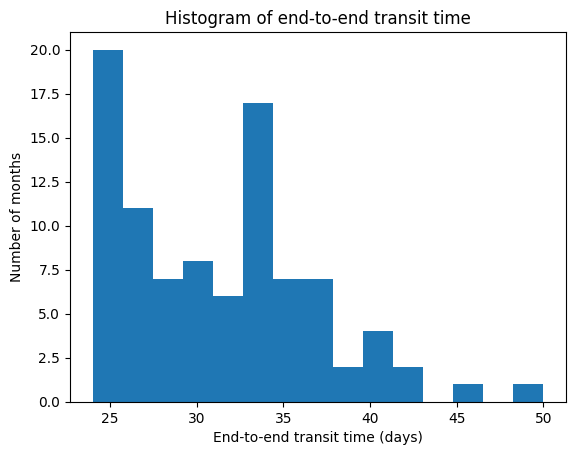

In [21]:
import matplotlib.pyplot as plt

plt.hist(df['e2e_transit_days'],bins=15)
plt.xlabel('End-to-end transit time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of end-to-end transit time')

Text(0.5, 1.0, 'Histogram of Port Dwell Time')

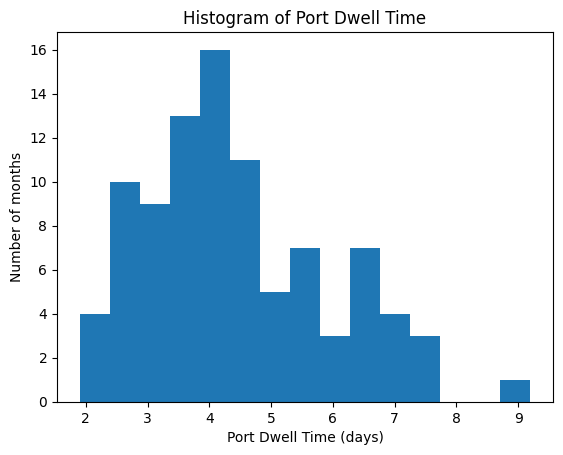

In [22]:
plt.hist(df['dwell_west_coast_days'],bins=15)
plt.xlabel('Port Dwell Time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of Port Dwell Time')

Text(0.5, 1.0, 'Histogram of transit time without port dwell')

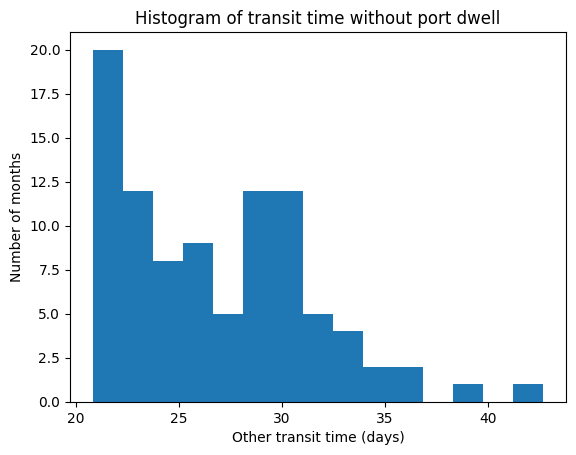

In [23]:
plt.hist(df['nondwell_days'],bins=15)
plt.xlabel('Other transit time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of transit time without port dwell')

Text(0.5, 1.0, 'Boxplots of transit, dwell, and non-dwell time')

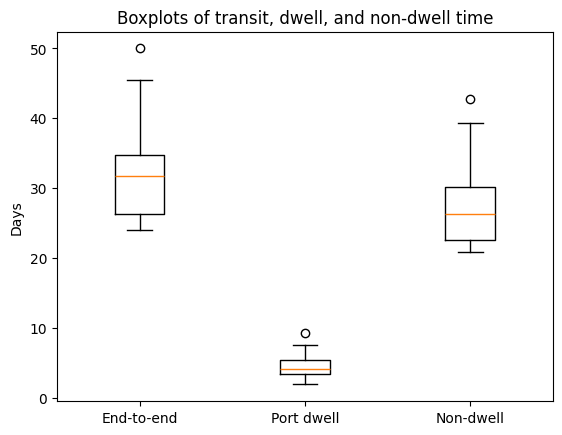

In [28]:
plt.boxplot(df[cols])
plt.xticks([1, 2, 3], ['End-to-end', 'Port dwell', 'Non-dwell'])
plt.ylabel('Days')
plt.title('Boxplots of transit, dwell, and non-dwell time')

In [29]:
def find_outliers(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return df[(df[column] < lower) | (df[column] > upper)][['date', column]]

for col in ['e2e_transit_days', 'dwell_west_coast_days', 'nondwell_days']:
    print(col)
    print(find_outliers(df, col))
    print()

e2e_transit_days
         date  e2e_transit_days
60 2022-01-01              50.0

dwell_west_coast_days
         date  dwell_west_coast_days
72 2023-01-01                    9.2

nondwell_days
         date  nondwell_days
60 2022-01-01           42.7

